<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


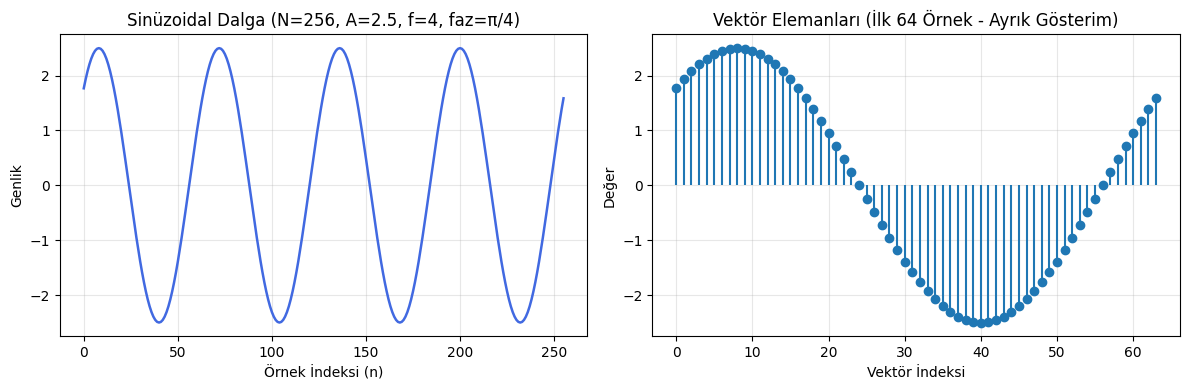

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def doldur_sinus(vec, amplitude=1.0, frequency=5.0, phase=0.0, fs=256.0):
    """
    Parametre olarak verilen vektörü (2'nin kuvveti uzunlukta)
    sinüs dalgası değerleriyle yerinde (in-place) doldurur.

    amplitude : Genlik (A)
    frequency : Frekans (Hz / döngü sayısı)
    phase     : Faz (radyan cinsinden)
    fs        : Örnekleme frekansı (varsayılan: vektör uzunluğu)
    """
    n = len(vec)
    if n <= 0 or (n & (n - 1)) != 0:
        raise ValueError("Vektör boyutu 2'nin kuvveti olmalıdır (örneğin 128, 256, 512, 1024).")

    t = np.arange(n, dtype=np.float64) / fs
    vec[:] = amplitude * np.sin(2.0 * np.pi * frequency * t + phase)
    return vec

N = 256
signal_vec = np.zeros(N, dtype=np.float64)

doldur_sinus(
    vec=signal_vec,
    amplitude=2.5,
    frequency=4.0,
    phase=np.pi / 4,
    fs=N
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(signal_vec, color='royalblue', linewidth=1.8)
plt.title(f'Sinüzoidal Dalga (N={N}, A=2.5, f=4, faz=π/4)')
plt.xlabel('Örnek İndeksi (n)')
plt.ylabel('Genlik')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.stem(np.arange(min(N, 64)), signal_vec[:min(N, 64)], basefmt=" ")
plt.title('Vektör Elemanları (İlk 64 Örnek - Ayrık Gösterim)')
plt.xlabel('Vektör İndeksi')
plt.ylabel('Değer')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()